# [실습] 트리 앙상블과 SHAP — 더 강한 모델, 그리고 그 모델 설명하기

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

# Chapter 5 실습. 해지 요인을 경영진에 어떻게 보고할까?

**필수 머신러닝 · Chapter 5**

| Part | 주제 |
| --- | --- |
| Part 1 | 트리를 모으면 강해진다 |
| Part 2 | 모델이 무엇을 보는가: 피처 중요도와 SHAP |
| Part 3 | SHAP을 읽을 때의 함정 |
| Part 4 | 경영진과 CS팀에 보고하기 |

## 분석 의뢰서

> **의뢰 부서**: 통신사 경영기획팀 (Chapter 1 CS팀 의뢰의 후속)
> **목적**: CS팀의 해지 예측 모델을 경영진 보고에 쓰려 한다. 경영진은 "누가 해지할 것인가"보다 "왜 해지하는가, 무엇을 바꿔야 하는가"를 알고 싶어 한다.
> **제약**: 보고서에 적은 요인을 근거로 요금제나 계약 정책을 바꾸는 결정이 내려질 수 있다. 틀린 요인을 적으면 비용이 든다.
> **질문**: 해지에 영향을 주는 요인은 무엇이며, 그 요인을 바꾸면 해지가 줄어드는가?

## 이 실습의 질문

> **경영진에 보고할 해지 요인 세 가지는 무엇이고, 그중 "바꾸면 해지가 줄어든다"고 말할 수 있는 것은 몇 개인가? 그리고 CS팀 상담원에게 줄 고객별 위험 신호는 어떻게 만들 것인가?**

## 이 노트북을 쓰는 법

| 표시 | 뜻 |
| --- | --- |
| **[직접 작성]** | 빈 코드 셀을 직접 채웁니다. 강의 교안의 코드를 보지 않고 먼저 써 보세요 |
| **[판단]** | 코드가 아니라 생각을 적는 칸입니다. 셀을 더블클릭해 `나의 답:` 뒤에 적으세요 |
| **[제공]** | 미리 채워 둔 코드입니다. 읽고 실행하세요 |
| **힌트** | 막혔을 때만 펼치세요 |
| **먼저 예상하기** | 결과를 보기 전에 예상을 적어 두고, 결과를 본 뒤 비교합니다 |

## 준비

Chapter 1의 Telco 데이터 `WA_Fn-UseC_-Telco-Customer-Churn.csv`를 이 노트북과 같은 폴더에 두세요. SHAP 라이브러리가 없다면 먼저 설치합니다(`pip install shap`).

이 실습은 앙상블 모델을 교차검증으로 여러 번 학습하므로, 몇몇 셀은 실행에 1분 안팎이 걸립니다.

In [1]:
# [제공] 이 실습에서 쓰는 라이브러리
import platform
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
import shap
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, average_precision_score

# 그래프의 한글 글꼴 (환경에 맞는 글꼴이 없으면 글자가 깨질 수 있습니다)
if platform.system() == "Windows":
    plt.rcParams["font.family"] = "Malgun Gothic"
elif platform.system() == "Darwin":
    plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

---
# Part 1. 트리를 모으면 강해진다

## 1-1. 준비

**[제공]** 데이터를 불러와 Chapter 1과 같은 방법(80 : 20, `random_state=42`, `stratify`)으로 나눕니다. 누적 요금(`TotalCharges`)은 Chapter 4에서 확인한 대로 해지 시점에 멈춘 스냅샷 값이라 쓰지 않습니다. 고객 ID(`customerID`)도 피처에서 뺍니다.

| 이름 | 뜻 |
| --- | --- |
| `num_cols` | 숫자 피처 3개: `tenure`(가입 기간), `MonthlyCharges`(월 요금), `SeniorCitizen`(고령 여부 0/1) |
| `cat_cols` | 범주 피처 15개 (계약 유형, 인터넷 종류, 결제 방법 등) |
| `features` | 두 목록을 합친 피처 18개 |

In [2]:
# [제공] 데이터 준비
df = pd.read_csv("/Users/limsunghun/python/DI/필수 머신러닝/1. 머신러닝이란 무엇인가/WA_Fn-UseC_-Telco-Customer-Churn.csv")
df["target"] = (df["Churn"] == "Yes").astype(int)
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df["target"])

num_cols = ["tenure", "MonthlyCharges", "SeniorCitizen"]
cat_cols = [c for c in df.columns if c not in num_cols + ["customerID", "Churn", "target", "TotalCharges"]]
features = num_cols + cat_cols
y_train, y_test = train_df["target"], test_df["target"]
print(len(train_df), len(test_df), "| 피처 수", len(features), "| 학습용 해지율", round(y_train.mean(), 3))

5634 1409 | 피처 수 18 | 학습용 해지율 0.265


### 실습 도구 (실행만 하세요)

| 도구 | 하는 일 |
| --- | --- |
| `make_pipe(모델, scale=True)` | 전처리(숫자 열 스케일링, 범주 열 원핫 인코딩)와 모델을 묶은 파이프라인을 만든다. 트리 계열은 `scale=False` |
| `evaluate_model(이름, 파이프라인)` | 5겹 교차검증 ROC AUC, 학습용 전체로 학습한 뒤의 평가용 ROC AUC·PR AUC, 학습용 ROC AUC를 결과표에 남기고, 학습된 파이프라인을 돌려준다 |
| `compare(이름 A, 모델 A, 이름 B, 모델 B)` | 두 모델을 같은 5겹으로 평가해 fold별 차이를 보여 준다 (Chapter 4) |
| `show_log()` | 결과표를 보여 준다 |

In [3]:
# [제공] 실습 도구
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []

def make_pipe(clf, scale=True):
    pre = ColumnTransformer([
        ("num", StandardScaler() if scale else "passthrough", num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ])
    return Pipeline([("pre", pre), ("clf", clf)])

def evaluate_model(name, model):
    s = cross_val_score(model, train_df[features], y_train, cv=cv, scoring="roc_auc")
    model.fit(train_df[features], y_train)
    p_te = model.predict_proba(test_df[features])[:, 1]
    p_tr = model.predict_proba(train_df[features])[:, 1]
    row = {"모델": name, "교차검증 AUC": f"{s.mean():.3f} ± {s.std():.3f}",
           "평가용 AUC": round(roc_auc_score(y_test, p_te), 3),
           "평가용 PR AUC": round(average_precision_score(y_test, p_te), 3),
           "학습용 AUC": round(roc_auc_score(y_train, p_tr), 3)}
    results.append(row)
    print(row)
    return model

def compare(name_a, model_a, name_b, model_b):
    s_a = cross_val_score(model_a, train_df[features], y_train, cv=cv, scoring="roc_auc")
    s_b = cross_val_score(model_b, train_df[features], y_train, cv=cv, scoring="roc_auc")
    diff = s_b - s_a
    print(f"{name_a}: {s_a.round(3)} | 평균 {s_a.mean():.3f} ± {s_a.std():.3f}")
    print(f"{name_b}: {s_b.round(3)} | 평균 {s_b.mean():.3f} ± {s_b.std():.3f}")
    print(f"fold별 차이 (B - A): {diff.round(3)} | 평균 차이 {diff.mean():+.3f}")
    print()

def show_log():
    return pd.DataFrame(results)

## 1-2. 지니 계수 손으로 계산하기

결정트리는 "나눈 뒤 섞임이 가장 많이 줄어드는 질문"을 고릅니다. 섞임은 지니 계수 $G = 2p(1-p)$로 잽니다($p$는 해지 비율).

**[직접 작성]** 학습용 데이터에서 다음을 계산해 출력하세요.

1. 함수 `gini(p)`: $2p(1-p)$를 돌려준다
2. 나누기 전의 지니 계수
3. "월 단위 계약인가"(`Contract == "Month-to-month"`)로 나눈 뒤 두 상자의 고객 수, 해지 비율, 지니 계수
4. 고객 수로 가중 평균한 나눈 뒤의 지니 계수 $G_{\text{split}}$와 감소량 $\Delta G$

<details><summary>힌트</summary>

```python
m = train_df["Contract"] == "Month-to-month"
p_left, p_right = y_train[m].mean(), y_train[~m].mean()
g_split = m.mean() * gini(p_left) + (~m).mean() * gini(p_right)
```
</details>

In [4]:
# 여기에 코드를 작성하세요

# 1. 지니 계수 함수
def gini(p):
    return 2 * p * (1 - p)

y = np.asarray(y_train, dtype=float)   # Series든 배열이든 같은 방식으로 다루기 위해 변환

# 2. 나누기 전
p0 = y.mean()
g0 = gini(p0)
print(f"[나누기 전] 고객 {len(y):,}명 | 해지 비율 {p0:.3f} | 지니 {g0:.4f}")

# 3. "월 단위 계약인가"로 나눈 뒤
m = (train_df["Contract"] == "Month-to-month").to_numpy()
p_left, p_right = y[m].mean(), y[~m].mean()

print(f"[월 단위 계약] 고객 {m.sum():,}명 | 해지 비율 {p_left:.3f} | 지니 {gini(p_left):.4f}")
print(f"[그 외 계약]   고객 {(~m).sum():,}명 | 해지 비율 {p_right:.3f} | 지니 {gini(p_right):.4f}")

# 4. 가중 평균 지니와 감소량
g_split = m.mean() * gini(p_left) + (~m).mean() * gini(p_right)
delta_g = g0 - g_split
print(f"[나눈 뒤] G_split = {g_split:.4f} | ΔG = {delta_g:.4f}")

[나누기 전] 고객 5,634명 | 해지 비율 0.265 | 지니 0.3899
[월 단위 계약] 고객 3,102명 | 해지 비율 0.427 | 지니 0.4895
[그 외 계약]   고객 2,532명 | 해지 비율 0.067 | 지니 0.1246
[나눈 뒤] G_split = 0.3255 | ΔG = 0.0644


> **[판단]** 월 단위 상자의 지니 계수는 나누기 전보다 커졌습니다. 그런데도 전체로는 섞임이 줄어든 이유는 무엇인가요?
>
> 나의 답:

나눈 뒤의 지니는 두 상자를 고객 수로 가중 평균한 값이다. 월 단위 상자는 해지 비율이 0.5 쪽으로 다가가 지니가 0.0996 늘었지만, 그외 계약 상자는 해지비율이 0.067로 떨어져 지니가 0.265나 줄었다. 깨끗해진 쪽의 효과가 더 커서 전체로는 0.064만큼 줄었다.

## 1-3. 트리 하나의 한계

### 먼저 예상하기

결과를 보기 전에 예상을 적어 두고, 결과를 본 뒤 비교합니다.

> **[판단]** 예상: 깊이 제한 없이 끝까지 자란 트리의 학습용 AUC와 평가용 AUC는 각각 얼마쯤일까요? 깊이 3 트리(평가용 약 0.82)보다 나을까요?
>
> 나의 답:

학습용 AUC는 1에 가까울 것 같고, 평가용 AUC는 0.65~0.70정도로 깊이 3 트리보다 확실히 나쁠 것 같다.

**[직접 작성]** `evaluate_model`로 결정트리 세 개(깊이 3, 깊이 6, 깊이 제한 없음)를 평가하세요. 트리는 스케일링이 필요 없으므로 `make_pipe(..., scale=False)`, `random_state=42`를 씁니다.

<details><summary>힌트</summary>

`evaluate_model("트리 깊이 3", make_pipe(DecisionTreeClassifier(max_depth=3, random_state=42), scale=False))`. 깊이 제한이 없으면 `max_depth=None`(기본값)입니다.
</details>

In [5]:
# 여기에 코드를 작성하세요

for name, depth in [("트리 깊이 3", 3), ("트리 깊이 6", 6), ("트리 깊이 제한 없음", None)]:
    evaluate_model(
        name,
        make_pipe(DecisionTreeClassifier(max_depth=depth, random_state=42), scale=False),
    )

{'모델': '트리 깊이 3', '교차검증 AUC': '0.817 ± 0.006', '평가용 AUC': 0.818, '평가용 PR AUC': 0.556, '학습용 AUC': 0.824}
{'모델': '트리 깊이 6', '교차검증 AUC': '0.824 ± 0.011', '평가용 AUC': 0.835, '평가용 PR AUC': 0.617, '학습용 AUC': 0.865}
{'모델': '트리 깊이 제한 없음', '교차검증 AUC': '0.659 ± 0.014', '평가용 AUC': 0.668, '평가용 PR AUC': 0.388, '학습용 AUC': 1.0}


> **[판단]** 예상은 맞았나요? 깊이 제한 없는 트리의 학습용 AUC와 평가용 AUC의 차이를 "편향"과 "분산" 중 무엇으로 설명할 수 있나요? 깊이 3 트리는 어느 쪽의 문제가 더 클까요?
>
> 나의 답:

예상이 맞았다.
학습용은 1 , 평가용은 0.668로 깊이 3 트리보다 크게 나빴다. 깊이 제한 없는 트리의 차이는 분산으로 설명된다. 학습 데이터를 외워 새 데이터에 일반화하지 못한 것이다. 깊이 3트리는 학습용과  평가용 AUC가 거의 같아 분산은 작지만, 학습용 AUC 자체가 0.824로 낮아 편향이 더 큰 문제다. 깊이 6에서 평가용 성능이 올라간 것이 깊이 3이 너무 단순했다는 증거다.

## 1-4. 트리들을 서로 다르게: 배깅과 랜덤포레스트

**[제공]** 전처리만 한 학습용·평가용 데이터(`X_tr_t`, `X_te_t`)를 만듭니다. 이 절과 1-6에서 씁니다.

In [6]:
# [제공] 전처리한 데이터 (트리용: 스케일링 없음)
pre_tree = ColumnTransformer([
    ("num", "passthrough", num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])
X_tr_t = pd.DataFrame(pre_tree.fit_transform(train_df[features]), columns=pre_tree.get_feature_names_out())
X_te_t = pd.DataFrame(pre_tree.transform(test_df[features]), columns=pre_tree.get_feature_names_out())
print(X_tr_t.shape, X_te_t.shape)

(5634, 44) (1409, 44)


**[직접 작성]** 부트스트랩 표본 20개를 만들고, 표본마다 깊이 3 트리 두 가지를 학습해 **첫 질문(맨 위 노드)에 쓰인 피처**를 세어 보세요.

- 배깅: `DecisionTreeClassifier(max_depth=3, random_state=b)`
- 피처 후보 제한(랜덤포레스트 방식): `DecisionTreeClassifier(max_depth=3, max_features="sqrt", random_state=b)`

<details><summary>힌트</summary>

```python
rng = np.random.RandomState(42)
idx = rng.randint(0, len(X_tr_t), len(X_tr_t))       # 복원 추출로 고른 행 번호
t = DecisionTreeClassifier(max_depth=3, random_state=b).fit(X_tr_t.iloc[idx], y_train.iloc[idx])
root = X_tr_t.columns[t.tree_.feature[0]]             # 첫 질문에 쓰인 피처 이름
```
</details>

In [7]:
# 여기에 코드를 작성하세요

from collections import Counter
from sklearn.tree import DecisionTreeClassifier

rng = np.random.RandomState(42)
y_arr = np.asarray(y_train)   # 인덱스 정렬 문제를 피하기 위해 배열로
n = len(X_tr_t)

roots_bag, roots_rf = Counter(), Counter()

for b in range(20):
    idx = rng.randint(0, n, n)                       # 같은 부트스트랩 표본을 두 트리에 똑같이 사용
    X_b, y_b = X_tr_t.iloc[idx], y_arr[idx]

    t_bag = DecisionTreeClassifier(max_depth=3, random_state=b).fit(X_b, y_b)
    t_rf = DecisionTreeClassifier(max_depth=3, max_features="sqrt", random_state=b).fit(X_b, y_b)

    roots_bag[X_tr_t.columns[t_bag.tree_.feature[0]]] += 1
    roots_rf[X_tr_t.columns[t_rf.tree_.feature[0]]] += 1

print("[배깅] 첫 질문 피처")
for feat, cnt in roots_bag.most_common():
    print(f"  {feat}: {cnt}")

print("\n[피처 후보 제한] 첫 질문 피처")
for feat, cnt in roots_rf.most_common():
    print(f"  {feat}: {cnt}")

[배깅] 첫 질문 피처
  cat__Contract_Month-to-month: 20

[피처 후보 제한] 첫 질문 피처
  num__tenure: 3
  cat__Contract_Month-to-month: 3
  cat__TechSupport_No internet service: 2
  cat__PaymentMethod_Electronic check: 2
  cat__TechSupport_No: 2
  cat__Contract_One year: 1
  cat__DeviceProtection_No internet service: 1
  cat__InternetService_Fiber optic: 1
  num__MonthlyCharges: 1
  cat__Contract_Two year: 1
  cat__PaperlessBilling_No: 1
  cat__StreamingMovies_No internet service: 1
  cat__StreamingTV_No internet service: 1


> **[판단]** 두 방법의 첫 질문은 어떻게 다른가요? 교안 1-3의 식 $\rho\sigma^2 + (1-\rho)\sigma^2/B$와 연결해, 피처 후보를 제한하면 왜 평균의 효과가 커지는지 설명해 보세요.
>
> 나의 답:

배깅은 20개 트리 모두 월 단위 계약으로 시작했지만, 피처 후보를 제한하자 첫 질문이 13가지로 나눠졌다. 평균의 분산 $\rho\sigma^2 + (1-\rho)\sigma^2/B$ 에서 첫째 항은 B를 늘려도 줄지 않는데, 배깅은 트리들이 비슷해  $\rho$ 가 크므로 바닥이 높다. 피처 후보를 제한하면 트리들이 서로 다르게 자라 $\rho$가 낮아지고, 바닥이 내려가 트리를 많이 평균할 수록 분산이 더 많이 줄어든다.


**[직접 작성]** `evaluate_model`로 랜덤포레스트 두 개를 평가하세요. 둘 다 `n_estimators=300, random_state=42, n_jobs=-1`이고, 하나는 기본값, 하나는 잎에 최소 20명(`min_samples_leaf=20`)입니다.

In [8]:
# 여기에 코드를 작성하세요

rf_params = dict(n_estimators=300, random_state=42, n_jobs=-1)

evaluate_model(
    "랜덤포레스트 기본",
    make_pipe(RandomForestClassifier(**rf_params), scale=False),
)
evaluate_model(
    "랜덤포레스트 잎 최소 20명",
    make_pipe(RandomForestClassifier(min_samples_leaf=20, **rf_params), scale=False),
)

{'모델': '랜덤포레스트 기본', '교차검증 AUC': '0.814 ± 0.012', '평가용 AUC': 0.814, '평가용 PR AUC': 0.598, '학습용 AUC': 1.0}
{'모델': '랜덤포레스트 잎 최소 20명', '교차검증 AUC': '0.846 ± 0.009', '평가용 AUC': 0.84, '평가용 PR AUC': 0.637, '학습용 AUC': 0.875}


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('pre', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](18,)","['tenure','MonthlyCharges','SeniorCitizen',...,'Contract', 'PaperlessBilling','PaymentMethod']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,18
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthro

> **[판단]** 기본값 랜덤포레스트의 학습용 AUC와 평가용 AUC를 보세요. "앙상블이니까 과적합하지 않는다"는 말은 맞나요? 잎의 최소 고객 수를 늘리면 무엇이 달라지나요?
>
> 나의 답:

맞지 않다.

기본 랜덤 포레스트는 학습용AUC 1, 평가용AUC 0.814로 큰 간격이 남아 과적합이다. 트리 수를 늘려서 과적합이 생기지는 않지만, 개별 트리가 끝까지 자라 학습 데이터를 외우면 그 공통된 오류는 평균으로 지워지지 않는다. 앞에 최소 20명을 여구하면 각 트리가 소수 고객을 외우지 못해 개별 트리의 분산이 줄어든다. 학습용AUC는 0.875로 내려갔지만 평가용AUC는 0.84로 올라 간격이 0.035로 좁아졌다.


## 1-5. 부스팅: 트리를 더할수록

**[직접 작성]** 경사 부스팅 모델 `GradientBoostingClassifier(n_estimators=500, learning_rate=0.1, max_depth=3, random_state=42)`를 `X_tr_t`로 학습하고, 트리를 1, 10, 50, 100, 200, 500개 더한 시점의 학습용 AUC와 평가용 AUC를 표로 출력하세요.

<details><summary>힌트</summary>

`staged_predict_proba`는 트리를 하나씩 더할 때마다의 확률을 차례로 돌려줍니다.
```python
for i, (p_tr, p_te) in enumerate(zip(gb.staged_predict_proba(X_tr_t), gb.staged_predict_proba(X_te_t)), start=1):
    if i in [1, 10, 50, 100, 200, 500]:
        ...  # p_tr[:, 1], p_te[:, 1]로 AUC 계산
```
</details>

In [9]:
# 여기에 코드를 작성하세요

gb = GradientBoostingClassifier(
    n_estimators=500, learning_rate=0.1, max_depth=3, random_state=42
).fit(X_tr_t, y_train)

checkpoints = {1, 10, 50, 100, 200, 500}
rows = []

stages = zip(gb.staged_predict_proba(X_tr_t), gb.staged_predict_proba(X_te_t))
for i, (p_tr, p_te) in enumerate(stages, start=1):
    if i in checkpoints:
        rows.append({
            "트리 수": i,
            "학습용 AUC": round(roc_auc_score(y_train, p_tr[:, 1]), 3),
            "평가용 AUC": round(roc_auc_score(y_test, p_te[:, 1]), 3),
        })

result = pd.DataFrame(rows).set_index("트리 수")
result["간격"] = result["학습용 AUC"] - result["평가용 AUC"]
print(result)

      학습용 AUC  평가용 AUC     간격
트리 수                         
1       0.824    0.818  0.006
10      0.849    0.839  0.010
50      0.868    0.844  0.024
100     0.879    0.843  0.036
200     0.895    0.838  0.057
500     0.930    0.828  0.102


> **[판단]** 트리 수를 늘릴 때 학습용과 평가용 AUC는 각각 어떻게 움직이나요? 랜덤포레스트의 트리 수와 무엇이 다른가요? 이 표를 보고 트리 수를 고르면 어떤 문제가 있을까요? (Chapter 4 3-1)
>
> 나의 답:

트리 수를 늘릴 때 마다 학습용AUC는 꾸준히 오르지만 평가용AUC는 오르다가 트리 수 50을 기점으로 내려간다.

랜덤포레스트는 독립적인 트리를 평균하므로 트리 수를 늘려도 과적합하지 않지만, 부스팅은 앞 트리의 오류를 순차적으로 고치므로 트리 수가 곧 복잡도이고 너무 많으면 과적합한다.


## 1-6. 더 강한 모델은 얼마나 강한가

**[직접 작성]** 두 가지를 하세요.

1. `evaluate_model`로 로지스틱 회귀(`make_pipe(LogisticRegression(max_iter=3000))`)와 경사 부스팅 기본값(`GradientBoostingClassifier(random_state=42)`, `scale=False`)을 평가하고, 부스팅 파이프라인을 `gbm_model`에 저장한 뒤 `show_log()`로 결과표를 보세요.
2. `compare`로 "트리 깊이 3 vs 경사 부스팅", "로지스틱 회귀 vs 경사 부스팅"을 비교하세요.

In [10]:
# 여기에 코드를 작성하세요

tree3_model = make_pipe(DecisionTreeClassifier(max_depth=3, random_state=42), scale=False)
logit_model = make_pipe(LogisticRegression(max_iter=3000))

compare("트리 깊이 3", tree3_model, "경사 부스팅", gbm_model)
compare("로지스틱 회귀", logit_model, "경사 부스팅", gbm_model)

NameError: name 'gbm_model' is not defined

> **[판단]** 앙상블은 트리 하나보다 분명히 나은가요? 로지스틱 회귀보다는 나은가요? Chapter 4의 기준(fold별 차이와 편차)으로 판단하세요. 성능만 본다면 어느 모델을 고르겠습니까?
>
> 나의 답:

앙상블은 트리 하나 보다 낫다. 다섯 fold 모두에서 양수값을 가졌으며 평규나이가 0.031dms fold별 차이의 표준편차의 4배쯤된다.
로지스틱회귀 봐다 낫다고 할 수 없다. 평균 차이는 +0.003이지만 fold별로 보면 음수값을 가지게 된다. fold별 차이의 표준편차가 약 0.0065로 평균 차이보다 두 배 이상 크고, 각 모델의 교차검증 편차와 비교해도 0.003은 잡음 안에 묻힌다. 두 모델의 성능은 비슷하다.

성능이 같다고 판단되면 더 단순한 모델인 로지스틱회귀모델 고르겠다. 성능이 구별되지 않는 상황에서 복잡한 모델을 택하면 얻는 것 없어 학습시간, 과적합 위험만 늘어난다.


> **[판단]** 그런데도 이 실습은 Part 2에서 경사 부스팅 모델을 설명에 씁니다. 성능이 비슷한데도 부스팅을 쓸 이유가 있다면 무엇일까요? (교안 1-7, 2-5)
>
> 나의 답:

로지스틱 회귀는 계수자체로 해석되지만 부스팅은 수많은 트리의 합이라 그대로는 해석할 수 없으므로, 설명 도구가 필요한 대상으로 적합하다. 또 부스팅은 관계의 모양을 직선으로 가정하지 않아 비선형 효과와 피처 간 상호작용을 학습할 수 있고, 설명 단계에서 이를 확인 할 수 있다. 성능이 비슷한 로지스틱회귀의 계수와 부스팅의 설명이 일치하는지 비교하면 설명이 데이터의 실제 패턴인지 검증할 수 있다.

---
# Part 2. 모델이 무엇을 보는가

이제부터 `gbm_model`(경사 부스팅 기본값)을 설명합니다.

## 2-1. 피처 중요도 두 가지

**[직접 작성]** 두 가지 중요도의 상위 5개를 출력하세요.

1. **불순도 중요도**: `gbm_model.named_steps["clf"].feature_importances_` (전처리 뒤의 열 이름은 `gbm_model.named_steps["pre"].get_feature_names_out()`)
2. **순열 중요도**: `permutation_importance(gbm_model, test_df[features], y_test, scoring="roc_auc", n_repeats=10, random_state=42)` (원래 피처 18개 기준)

<details><summary>힌트</summary>

결과를 `pd.Series(값, index=이름).sort_values(ascending=False).head(5)`로 정리하면 보기 쉽습니다. 순열 중요도의 값은 `.importances_mean`입니다.
</details>

In [ ]:
# 여기에 코드를 작성하세요

# evaluate_model이 내부에서 복제본을 학습했을 수 있으므로, 학습용 전체로 확실히 학습해 둔다
gbm_model.fit(train_df[features], y_train)

# 1. 불순도 중요도 (전처리 뒤의 열 기준)
imp_impurity = pd.Series(
    gbm_model.named_steps["clf"].feature_importances_,
    index=gbm_model.named_steps["pre"].get_feature_names_out(),
).sort_values(ascending=False)

print("[불순도 중요도] 상위 5개")
print(imp_impurity.head(5).round(4))

# 2. 순열 중요도 (원래 피처 18개 기준, 평가용 데이터)
perm = permutation_importance(
    gbm_model, test_df[features], y_test,
    scoring="roc_auc", n_repeats=10, random_state=42,
)
imp_perm = pd.Series(perm.importances_mean, index=features).sort_values(ascending=False)

print("\n[순열 중요도] 상위 5개 (AUC 감소량)")
print(imp_perm.head(5).round(4))

[불순도 중요도] 상위 5개
cat__Contract_Month-to-month        0.3855
num__tenure                         0.1820
num__MonthlyCharges                 0.1012
cat__InternetService_Fiber optic    0.0896
cat__OnlineSecurity_No              0.0693
dtype: float64

[순열 중요도] 상위 5개 (AUC 감소량)
Contract           0.0760
tenure             0.0722
InternetService    0.0088
MonthlyCharges     0.0074
OnlineSecurity     0.0058
dtype: float64


> **[판단]** 두 중요도의 순위는 어떻게 다른가요? 두 중요도로는 답할 수 없는 질문을 두 가지 적어 보세요. (예: 가입 기간이 길면 해지 확률이 오르나, 내리나?)
>
> 나의 답:

두 중요도 모두 계약형태와 가입기간이 1,2등이다. 하지만 불순도 중요도에서는 월단위 계약이 가입기간의 두배가 넘는 반면, 순열 중요도에서는 계약과 기입기간의 바슷하다. 또 불순도 중요도는 3위 이하로 꽤 큰 점수를 받지만 순열 중요도는 상위 두 개 뒤로 0.01 아래로 급격히 떨어진다.

불순도 중요도는 학습용 데이터에서 트리가 나눌 때 줄인 지니계수의 합이라, 첫 질문으로 자주 쓰인 피처에 점수가 몰리고 나눌 지점이 많은 연속형 피처를 과대평가한다. 순열 중요도는 평가용 데이터에서 그 피처를 섞었을 대 실제로 잃는 AUC라서, 성능을 실제로 떠받치는 건 계약 형태와 가입 기간 두 개뿐임을 보여준다.

중요도로는 답할 수없는 질문은 가입 기간이 길면 해지 확룰이 오르는가? 내리는가?, 월 요금이 오를 수록 해지 확률이 꾸준히 오르는가, 특정 금액을 넘을 때만 뛰는가?

## 2-2. SHAP 값 계산하고 가산성 확인하기

**[직접 작성]**

1. 평가용 데이터를 `gbm_model`의 전처리로 바꿔 `X_test_t`(열 이름이 붙은 DataFrame)를 만드세요.
2. `shap.TreeExplainer`로 `shap_values`(고객 수 × 피처 수)와 `base_value`(기준값)를 계산하세요.
3. 평가용 첫 고객에서 "기준값 + 기여도 합"과 모델의 로그 오즈 출력(`decision_function`)이 같은지 확인하세요.

<details><summary>힌트</summary>

```python
pre, gbm = gbm_model.named_steps["pre"], gbm_model.named_steps["clf"]
X_test_t = pd.DataFrame(pre.transform(test_df[features]), columns=pre.get_feature_names_out())
explainer = shap.TreeExplainer(gbm)
shap_values = explainer.shap_values(X_test_t)
base_value = float(np.ravel(explainer.expected_value)[0])
```
</details>

In [ ]:
# 여기에 코드를 작성하세요

# 1. 평가용 데이터를 전처리 뒤의 형태로 변환
pre, gbm = gbm_model.named_steps["pre"], gbm_model.named_steps["clf"]
X_te_arr = pre.transform(test_df[features])
if hasattr(X_te_arr, "toarray"):          # 원-핫 인코딩 결과가 희소 행렬이면 일반 배열로
    X_te_arr = X_te_arr.toarray()
X_test_t = pd.DataFrame(X_te_arr, columns=pre.get_feature_names_out(), index=test_df.index)

# 2. SHAP 값과 기준값
explainer = shap.TreeExplainer(gbm)
shap_values = explainer.shap_values(X_test_t)
if isinstance(shap_values, list):         # 버전에 따라 클래스별 리스트로 나올 때 대비
    shap_values = shap_values[1]
base_value = float(np.ravel(explainer.expected_value)[0])

print("shap_values 모양:", shap_values.shape)
print(f"기준값(로그 오즈): {base_value:.4f}")

# 3. 첫 고객에서 가산성 확인
shap_sum = base_value + shap_values[0].sum()
model_out = gbm.decision_function(X_test_t.iloc[[0]])[0]

print(f"\n기준값 + 기여도 합 : {shap_sum:.6f}")
print(f"모델 로그 오즈 출력: {model_out:.6f}")
print("일치 여부:", np.isclose(shap_sum, model_out))

shap_values 모양: (1409, 44)
기준값(로그 오즈): -1.5942

기준값 + 기여도 합 : -3.938199
모델 로그 오즈 출력: -3.938199
일치 여부: True


> **[판단]** 기준값을 확률로 바꾸면 얼마인가요? ($p = 1/(1 + e^{-z})$) 학습용 해지율(약 0.265)과 같나요? 다르다면 왜 다를까요? (교안 3-2)
>
> 나의 답:

기준값: 0.169가 나와서 학습용 해지율 보다 낮게 나왔다.

기준값은 모델 출력인 로그 오즈를 평균한 값이고 해지율은 확률을 평균한 값인데, 시그모이드가 고선이라 두 평균이 같지 않다. 해지 가능성이 아주 낮은 고객은 확률로는 0 근처에 모이지만 로그 오즈로는 큰 음수가 되어 로그 오즈 평균을 크게 끌어내리기 떄문이다.


## 2-3. 전체 그림: bar와 beeswarm

**[직접 작성]** 피처별 기여도 **절댓값의 평균**을 계산해 상위 8개를 출력하고, `shap.summary_plot(shap_values, X_test_t, max_display=10)`로 beeswarm 그래프를 그리세요.

In [12]:
# 여기에 코드를 작성하세요

# 경사 부스팅 모델 다시 만들고 학습
gbm_model = make_pipe(GradientBoostingClassifier(random_state=42), scale=False)
gbm_model.fit(train_df[features], y_train)

# 2-2의 SHAP 계산 다시 실행
pre, gbm = gbm_model.named_steps["pre"], gbm_model.named_steps["clf"]
X_te_arr = pre.transform(test_df[features])
if hasattr(X_te_arr, "toarray"):
    X_te_arr = X_te_arr.toarray()
X_test_t = pd.DataFrame(X_te_arr, columns=pre.get_feature_names_out(), index=test_df.index)

explainer = shap.TreeExplainer(gbm)
shap_values = explainer.shap_values(X_test_t)
if isinstance(shap_values, list):
    shap_values = shap_values[1]
base_value = float(np.ravel(explainer.expected_value)[0])

[평균 |SHAP|] 상위 8개 (로그 오즈 단위)
cat__Contract_Month-to-month           0.6392
num__tenure                            0.5065
cat__OnlineSecurity_No                 0.2419
num__MonthlyCharges                    0.2259
cat__TechSupport_No                    0.2073
cat__InternetService_Fiber optic       0.1987
cat__Contract_Two year                 0.1687
cat__PaymentMethod_Electronic check    0.1676
dtype: float64


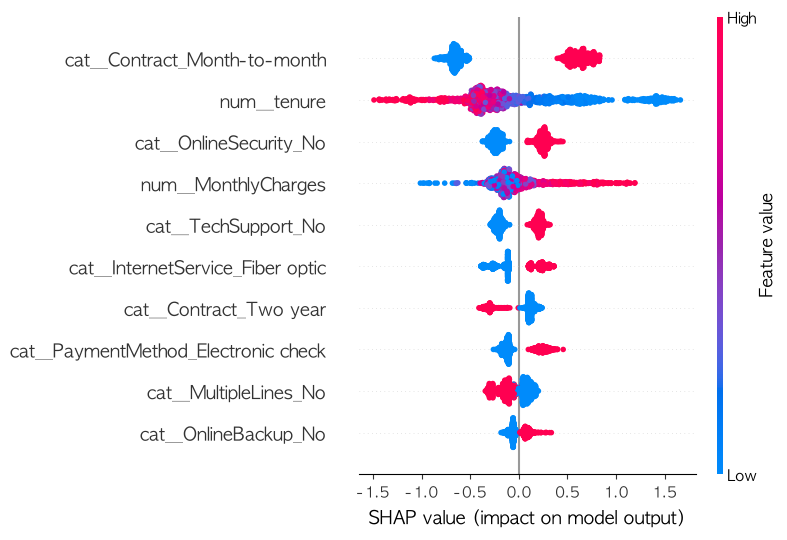

In [13]:
# 피처별 |SHAP| 평균 (로그 오즈 단위)
mean_abs_shap = pd.Series(
    np.abs(shap_values).mean(axis=0), index=X_test_t.columns
).sort_values(ascending=False)

print("[평균 |SHAP|] 상위 8개 (로그 오즈 단위)")
print(mean_abs_shap.head(8).round(4))

# beeswarm 그래프
shap.summary_plot(shap_values, X_test_t, max_display=10)

> **[판단]** beeswarm 그래프에서 월 단위 계약(`cat__Contract_Month-to-month`)과 가입 기간(`num__tenure`)의 점은 각각 어느 쪽에 모여 있나요? 색(빨강 = 값이 큼)과 함께 읽어, "이 값이 크면 모델은 해지 확률을 올리는가, 내리는가"를 두 피처에 대해 적으세요.
>
> 나의 답:

월 단위 계약은 빨강색이 오른쪽, 파란색이 왼쪽으로 모여있고, 가입기간은 빨간색이 왼쪽에 있지만 파란색은 왼쪽에서부터 오른쪽까지 퍼져있는 형태이다. 가입기간이 길수록 모델은 해지확률을 내미려, 특히 가입 초기 고객에게서 해지쪽으로 미는 효과가 크다.

## 2-4. 어디서 꺾이는가: dependence

**[직접 작성]** 가입 기간과 월 요금의 기여도를 구간별로 평균해 표로 출력하세요.

- 가입 기간 구간: `[0, 6, 12, 24, 48, 72]` (개월)
- 월 요금 구간: `[0, 40, 70, 90, 120]` (달러)

<details><summary>힌트</summary>

```python
tenure_shap = pd.Series(shap_values[:, list(X_test_t.columns).index("num__tenure")])
tenure_bin = pd.cut(X_test_t["num__tenure"], [0, 6, 12, 24, 48, 72], include_lowest=True)
tenure_shap.groupby(tenure_bin.values, observed=True).mean()
```
</details>

In [14]:
# 여기에 코드를 작성하세요

def shap_by_bin(col, bins):
    """한 피처의 SHAP 값을 구간별로 평균해 표로 돌려준다."""
    j = list(X_test_t.columns).index(col)
    df = pd.DataFrame({
        "구간": pd.cut(X_test_t[col].to_numpy(), bins, include_lowest=True),
        "SHAP": shap_values[:, j],
    })
    return (
        df.groupby("구간", observed=True)["SHAP"]
          .agg(고객수="size", 평균기여도="mean")
          .round({"평균기여도": 3})
    )

print("[가입 기간(개월)별 평균 기여도, 로그 오즈]")
print(shap_by_bin("num__tenure", [0, 6, 12, 24, 48, 72]))

print("\n[월 요금(달러)별 평균 기여도, 로그 오즈]")
print(shap_by_bin("num__MonthlyCharges", [0, 40, 70, 90, 120]))

[가입 기간(개월)별 평균 기여도, 로그 오즈]
               고객수  평균기여도
구간                       
(-0.001, 6.0]  311  0.951
(6.0, 12.0]    138  0.325
(12.0, 24.0]   206 -0.027
(24.0, 48.0]   304 -0.283
(48.0, 72.0]   450 -0.579

[월 요금(달러)별 평균 기여도, 로그 오즈]
                고객수  평균기여도
구간                        
(-0.001, 40.0]  372 -0.164
(40.0, 70.0]    339 -0.143
(70.0, 90.0]    365 -0.049
(90.0, 120.0]   333  0.459


> **[판단]** 가입 기간의 기여도는 어느 구간에서 가장 크고, 어디쯤에서 0을 지나나요? 월 요금은 "높을수록 해지"라고 말할 수 있나요, 아니면 특정 금액 위에서만 그런가요? 이 결과를 CS팀에 어떤 행동 지침으로 전하겠습니까?
>
> 나의 답:

가입기간의 기여도는 0~6개월 구간에서 가장크다. 12~24개월 구간에서 0을 지나 이후 음수로 내려간다. 효과가 가입 초기에 몰려있다. 
월요금은 높을 수록 해지라고 말하기 어렵다. 90달러까지는  모두 음이고 차이가 적다. 90달러를 넘는 구간에서만 양수로 바뀐다. 90달러 이상 고객은 여러가지 부가 서비스를 쓰는 경우가 많을 것이므로, 이 상승에는 요금 자체뿐 아니라 그런 고객 특성이 함께 섞여 있을 수있다.

## 2-5. 고객 한 명: waterfall

**[직접 작성]** 평가용 고객 중 모델이 해지 확률을 **가장 높게** 매긴 고객을 찾아, 그 고객의 해지 확률과 가입 기간·계약·월 요금을 출력하고, waterfall 그래프를 그리세요.

<details><summary>힌트</summary>

```python
prob = gbm_model.predict_proba(test_df[features])[:, 1]
i = int(np.argmax(prob))
shap.plots.waterfall(shap.Explanation(values=shap_values[i], base_values=base_value,
                                      data=X_test_t.iloc[i], feature_names=list(X_test_t.columns)))
```
</details>

평가용 1090번째 고객
  예측 해지 확률 : 0.917
  가입 기간      : 1개월
  계약           : Month-to-month
  월 요금        : $95.10
  실제 해지 여부 : 1


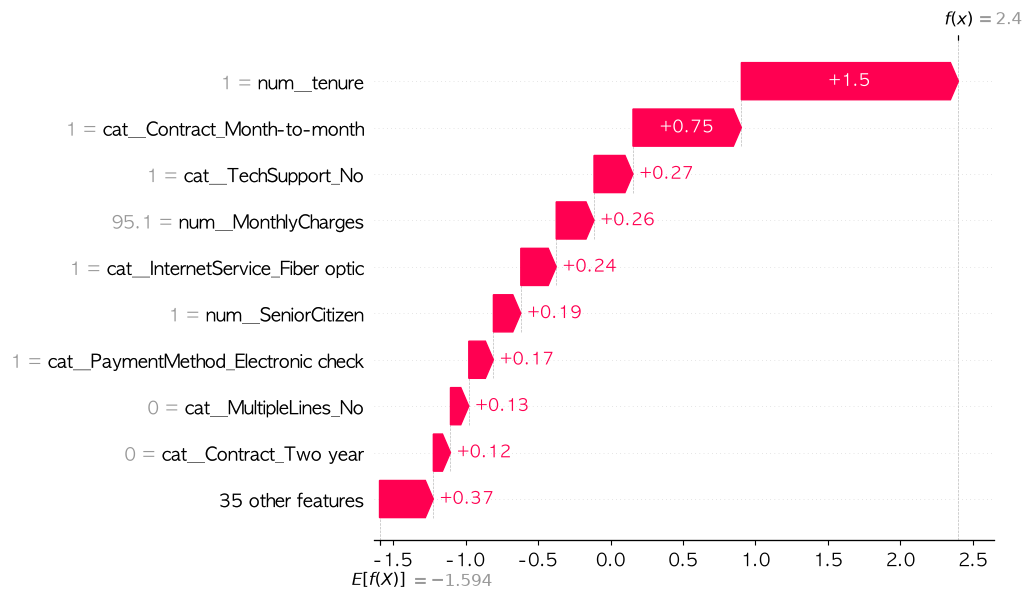

In [15]:
# 여기에 코드를 작성하세요

# 해지 확률이 가장 높은 평가용 고객 찾기
prob = gbm_model.predict_proba(test_df[features])[:, 1]
i = int(np.argmax(prob))
cust = test_df[features].iloc[i]

print(f"평가용 {i}번째 고객")
print(f"  예측 해지 확률 : {prob[i]:.3f}")
print(f"  가입 기간      : {cust['tenure']}개월")
print(f"  계약           : {cust['Contract']}")
print(f"  월 요금        : ${cust['MonthlyCharges']:.2f}")
print(f"  실제 해지 여부 : {np.asarray(y_test)[i]}")

# waterfall 그래프 (로그 오즈 단위)
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[i],
        base_values=base_value,
        data=X_test_t.iloc[i].to_numpy(),
        feature_names=list(X_test_t.columns),
    ),
    max_display=10,
)

> **[판단]** 이 고객에게 전화할 CS팀 상담원에게, 이 그래프를 한 문장으로 바꿔 전해 보세요. 그 문장에 "이것을 바꾸면 해지하지 않는다"는 뜻이 들어가지 않도록 주의하세요.
>
> 나의 답:

이 고객은 가입한 지 1개월 된 월 단위 계약 고객이라는 점이 해지 우히머 판단에 가장크게 작용했고, 기술지원 미가입, 월 95달러의 높은 요금, 고령고객, 전자 수표결제가 조금씩 더 해져 모델은 이 고객을 해지 확률 약 92%의 최고 위험으로 보고있다.

---
# Part 3. SHAP을 읽을 때의 함정

## 3-1. 상관 피처가 기여도를 나눠 가진다

### 먼저 예상하기

결과를 보기 전에 예상을 적어 두고, 결과를 본 뒤 비교합니다. 월 요금과 광케이블 인터넷은 정보가 많이 겹치는 피처입니다(광케이블 요금이 비쌈).

> **[판단]** 예상: 월 요금을 모델에서 빼고 다시 학습하면, 광케이블 인터넷(`cat__InternetService_Fiber optic`)의 기여도 절댓값 평균은 지금(2-3)보다 커질까요, 작아질까요, 그대로일까요?
>
> 나의 답:

커질 것 이다.

**[직접 작성]** 다음을 계산해 출력하세요.

1. 평가용 데이터에서 월 요금과 "광케이블 여부(0/1)"의 상관계수
2. 현재 모델에서 두 피처의 기여도 절댓값 평균, 그리고 고객마다 두 기여도를 **더한 뒤** 절댓값의 평균
3. 월 요금을 뺀 피처로 경사 부스팅을 다시 학습했을 때, 광케이블의 기여도 절댓값 평균과 평가용 AUC

<details><summary>힌트</summary>

3번은 `num_cols`에서 월 요금을 뺀 전처리를 새로 만들어야 합니다. 이 셀 안에서 `ColumnTransformer`를 직접 만들고, `TreeExplainer`도 새 모델로 다시 만듭니다.
</details>

In [17]:
# 여기에 코드를 작성하세요

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score
from sklearn.ensemble import GradientBoostingClassifier
import shap

cols = list(X_test_t.columns)
j_mc, j_fo = cols.index("num__MonthlyCharges"), cols.index("cat__InternetService_Fiber optic")

# 1. 월 요금과 광케이블 여부의 상관계수 (평가용)
fiber = (test_df["InternetService"] == "Fiber optic").astype(int)
print(f"[1] 상관계수(월 요금, 광케이블 여부): {test_df['MonthlyCharges'].corr(fiber):.3f}")

# 2. 현재 모델에서의 기여도
s_mc, s_fo = shap_values[:, j_mc], shap_values[:, j_fo]
print("\n[2] 현재 모델 (로그 오즈 단위)")
print(f"  월 요금   |SHAP| 평균        : {np.abs(s_mc).mean():.4f}")
print(f"  광케이블  |SHAP| 평균        : {np.abs(s_fo).mean():.4f}")
print(f"  두 값의 합                   : {np.abs(s_mc).mean() + np.abs(s_fo).mean():.4f}")
print(f"  |월 요금 + 광케이블| 평균     : {np.abs(s_mc + s_fo).mean():.4f}")

# 3. 월 요금을 뺀 모델
features2 = [f for f in features if f != "MonthlyCharges"]
orig_pre = gbm_model.named_steps["pre"]
pre2 = ColumnTransformer(
    [
        (name, tf if isinstance(tf, str) else clone(tf), [c for c in c_list if c != "MonthlyCharges"])
        for name, tf, c_list in orig_pre.transformers
    ],
    remainder=orig_pre.remainder,
)
gbm2_model = Pipeline([("pre", pre2), ("clf", GradientBoostingClassifier(random_state=42))])
gbm2_model.fit(train_df[features2], y_train)

X2_arr = gbm2_model.named_steps["pre"].transform(test_df[features2])
if hasattr(X2_arr, "toarray"):
    X2_arr = X2_arr.toarray()
X2_test_t = pd.DataFrame(X2_arr, columns=gbm2_model.named_steps["pre"].get_feature_names_out())

shap2 = shap.TreeExplainer(gbm2_model.named_steps["clf"]).shap_values(X2_test_t)
if isinstance(shap2, list):
    shap2 = shap2[1]
j_fo2 = list(X2_test_t.columns).index("cat__InternetService_Fiber optic")

auc_full = roc_auc_score(y_test, gbm_model.predict_proba(test_df[features])[:, 1])
auc_no_mc = roc_auc_score(y_test, gbm2_model.predict_proba(test_df[features2])[:, 1])

print("\n[3] 월 요금을 뺀 모델")
print(f"  광케이블 |SHAP| 평균 : {np.abs(shap2[:, j_fo2]).mean():.4f}  (현재 모델 {np.abs(s_fo).mean():.4f})")
print(f"  평가용 AUC           : {auc_no_mc:.3f}  (현재 모델 {auc_full:.3f})")

[1] 상관계수(월 요금, 광케이블 여부): 0.785

[2] 현재 모델 (로그 오즈 단위)
  월 요금   |SHAP| 평균        : 0.2259
  광케이블  |SHAP| 평균        : 0.1987
  두 값의 합                   : 0.4246
  |월 요금 + 광케이블| 평균     : 0.3853

[3] 월 요금을 뺀 모델
  광케이블 |SHAP| 평균 : 0.3906  (현재 모델 0.1987)
  평가용 AUC           : 0.847  (현재 모델 0.843)


> **[판단]** 예상은 맞았나요? 월 요금을 뺐을 때 광케이블의 기여도와 AUC가 어떻게 변했는지로, "해지 요인은 월 요금인가, 광케이블인가"라는 질문에 SHAP이 답할 수 있는지 판단하세요. 보고서에는 두 피처를 어떻게 적겠습니까?
>
> 나의 답:

예상이 맞았다. 월 요금을 뺀 광케이블의 기여도가 거의 두배 가까이 올랐다. 현재 모델에서 두 기여도를 더한 값의 평균과 거의 같다. AUC는 거의 변하지 않았다. SHAP으로 해지 요인이 월 요금인지 광케이블인지 판달할 수 없다. 보고서에는 두 피처를 광케이블, 고요금, 고객 이라는 하나의 묶음으로 합산 기여도와 함께 적고, 둘을 분리할 수 없다는 점을 밝히겠다.

## 3-2. 단위는 로그 오즈

**[제공]** 같은 기여도(+1.0)가 출발 확률에 따라 확률을 얼마나 바꾸는지 계산합니다.

In [ ]:
# [제공] 같은 기여도 +1.0, 다른 확률 변화
sigmoid = lambda z: 1 / (1 + np.exp(-z))
rows = []
for z in [-3, -2, -1, 0, 1]:
    rows.append({"출발 로그 오즈": z, "출발 확률": round(sigmoid(z), 3),
                 "+1.0 뒤의 확률": round(sigmoid(z + 1), 3), "확률 변화 (%p)": round((sigmoid(z + 1) - sigmoid(z)) * 100, 1)})
pd.DataFrame(rows)

,출발 로그 오즈,출발 확률,+1.0 뒤의 확률,확률 변화 (%p)
0,-3,0.047,0.119,7.2
1,-2,0.119,0.269,15.0
2,-1,0.269,0.500,23.1
3,0,0.500,0.731,23.1
4,1,0.731,0.881,15.0


> **[판단]** 어떤 보고서에 "월 단위 계약은 해지 확률을 평균 25%p 올린다"고 적혀 있습니다. 위 표를 근거로 이 문장의 문제를 설명하고, 같은 내용을 정직하게 바꿔 써 보세요.
>
> 나의 답:

표에서 같은 로그오즈 +1이 출발점에 따라 7.2%p에서 23.1%p까지 다른확률 변화를 만든다. 따라서 월 단위 계약의 효과를 "평균 몇 %p"라는 하나의 숫자로 말할 수 없고, 고객의 다른 조건에 따라 크게 달란지다. 또 "올린다"는 인과처럼 읽히지만 SHAP은 모델의 계산 방식을 보열 줄 뿐이다. 

정직하게 쓰면 "모델은 월 단위 계약 고객의 해지 예측을 로그 오즈로 약 +0.4~ +0.85높게 계산했으며, 확률로 확산한 크기는 원래 위험이 낮은 고객에게서 수 %p, 중간 위험 고객에서 10~20%p 수준으로 고객마다 다르다. 이는 계약을 바꾸면 해지가 줄어든다는 뜻은 아니다.


## 3-3. 보고서 문장 판별하기

다음 문장들이 Part 2의 SHAP 결과로 **쓸 수 있는 문장인지** 판단하세요. 쓸 수 없다면 어떤 함정(인과, 로그 오즈 단위, 상관 피처, 틀린 모델)에 걸렸는지 적습니다.

1. "모델은 월 단위 계약, 짧은 가입 기간, 온라인 보안 미가입을 해지 위험의 주요 신호로 사용한다."
2. "월 단위 고객을 2년 계약으로 전환시키면 해지가 줄어든다."
3. "해지 요인은 월 요금이 아니라 인터넷 종류다."
4. "가입 6개월 이내 고객의 해지 위험이 가장 높다."
5. "온라인 보안 서비스를 무료로 제공해 해지가 줄어드는지, 일부 고객에게 무작위로 시범 적용해 확인할 것을 제안한다."

> **[판단]** 1~5번 각각: 쓸 수 있다 / 쓸 수 없다(걸린 함정)
>
> 나의 답:

1. 쓸 수 있다.
2. 쓸 수 없다.
3. 쓸 수 없다.
4. 쓸 수 있다.
5. 쓸 수 있다.

---
# Part 4. 경영진과 CS팀에 보고하기

## 4-1. CS팀용 고객별 위험 신호

**[직접 작성]** 평가용 고객 중 해지 확률 상위 10명을 골라, 고객마다 **해지 확률을 가장 많이 올린 피처 3개**(기여도가 큰 양수 순)를 표로 만드세요. 표에는 고객 ID, 해지 확률, 위험 신호 1~3(피처 이름과 기여도)을 넣습니다.

<details><summary>힌트</summary>

```python
top10 = np.argsort(-prob)[:10]
s = pd.Series(shap_values[i], index=X_test_t.columns).sort_values(ascending=False).head(3)
```
</details>

In [ ]:
# 여기에 코드를 작성하세요

> **[판단]** 이 표를 상담원이 그대로 쓰기에는 무엇이 불편한가요? (예: 열 이름, 숫자의 단위) 상담원용으로 바꾼다면 위험 신호 열을 어떤 말로 바꾸겠습니까? 한 고객을 골라 예를 들어 보세요.
>
> 나의 답:

## 4-2. 경영진 보고 메모

분석 결과를 경영기획팀장에게 메시지로 보낸다고 생각하고 쓰세요. 팀장은 머신러닝 용어를 모릅니다. 아래 네 가지가 모두 들어가야 합니다.

1. **모델이 해지 위험 신호로 쓰는 요인 세 가지**: 근거 숫자(순위, 방향, 꺾이는 지점)와 함께
2. **"바꾸면 해지가 줄어든다"고 말할 수 있는 요인의 수**: 몇 개이고 왜 그런지
3. **제안**: 무엇을 어떻게 확인할 것인지 (실험)
4. **주의할 점**: 상관 피처, 모델의 한계(성능이 로지스틱 회귀와 비슷함 등)

> **[판단]** 경영진 보고 메모:
>
> 1. 모델이 쓰는 해지 위험 신호 세 가지:
>
> 2. "바꾸면 해지가 줄어든다"고 말할 수 있는 요인:
>
> 3. 제안:
>
> 4. 주의할 점:
>
> 나의 답:

---
# 마무리

## 이 Chapter의 판단 포인트

> **SHAP이 큰 요인은 모델이 많이 쓴 요인이지 해지의 원인이 아니다. "요인을 바꾸면 결과가 바뀌는가"는 실험으로 확인한다.**

## 개인 검증 체크리스트에 추가

오늘 실습에서 내가 실제로 겪은 일을 바탕으로, 체크리스트의 줄을 내 말로 적으세요.

예: "SHAP 결과를 보고서에 옮길 때 '요인'을 '원인'으로 바꿔 쓰지 않았는지 확인한다."

> **[판단]** 나의 체크리스트 8번(더 강한 모델을 고를 때):
>
> 나의 답:

> **[판단]** 나의 체크리스트 9번(모델 설명을 보고할 때):
>
> 나의 답:

## 제출물

- 이 노트북 (모든 **[판단]** 칸을 채운 상태)

수고했습니다. 다음 Chapter 6부터는 정답이 없는 데이터를 다루는 비지도학습입니다. 고객을 묶고, 그 묶음을 의심하는 법을 배웁니다.